# RQ2 analysis

Research question 2 analysis over the LVVI3 survey and YouTube data.

- **Inputs**: `data/LVVI3/lvvi3_survey_en.csv` (main LVVI3 survey table), `data/YouTube/youtube_videos.csv`, `data/YouTube/nbt_videos_in_state_owned_lands_cleaned.csv`, and `data/YouTube/clef_labels/youtube_clef_analysis.csv` (clef-model activity labels: `activity` + `structural_activity`; `accompany_type` was carried over from the archived Qwen3-VL run — the clef model covers activities only).
- **Outputs**: none — analysis only (may write auxiliary files such as `video_ids.txt`).


# Load packages

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

# Read data

## Read LVVI3 data

In [2]:
df_lvvi3 = pd.read_csv('../../data/LVVI3/lvvi3_survey_en.csv')
df_lvvi3 = df_lvvi3.rename(columns={'area_municipality': 'municipality'})

## Read YouTube data

In [3]:
# Read cleaned data and get the video id list
df_videos = pd.read_csv('../../data/YouTube/nbt_videos_in_state_owned_lands_cleaned.csv')
ls_video_id = df_videos.video_id.tolist()

# Read the geopackage file and keep the cleaned data
gdf_videos = gpd.read_file('../../data/YouTube/nbt_videos_in_state_owned_lands.gpkg')
gdf_videos = gdf_videos[gdf_videos['video_id'].isin(ls_video_id)]
gdf_videos.shape

(6110, 29)

In [4]:
# Read clef-model activity labels (long format: one row per video x activity)
df_clef = pd.read_csv("../../data/YouTube/clef_labels/youtube_clef_analysis.csv")

df_youtube = df_clef.merge(gdf_videos[['video_id', 'title', 'description', 'channel_id', 'channel_title',
                                             'comment_count', 'like_count', 'view_count', 'duration',
                                             'datetime', 'year', 'month', 'year_month', 'municipality',
                                             'nature_reserve', 'national_park', 'wilderness_area', 'commercial_forest',
                                             'geometry']], on='video_id', how='left')

df_youtube = gpd.GeoDataFrame(df_youtube, geometry='geometry')

df_youtube_nr = df_youtube[df_youtube['nature_reserve']==1]
df_youtube_np = df_youtube[df_youtube['national_park']==1]
df_youtube_wa = df_youtube[df_youtube['wilderness_area']==1]
df_youtube_cf = df_youtube[df_youtube['commercial_forest']==1]


In [5]:
df = pd.read_csv("../../data/YouTube/youtube_videos.csv")
df.shape

(3848, 29)

In [6]:
df_clef = pd.read_csv("../../data/YouTube/clef_labels/youtube_clef_analysis.csv")
ls_vid = df_clef.video_id.tolist()
ls_vid = list(set(ls_vid))

In [7]:
with open('video_ids.txt', 'w') as f:
    for vid in ls_vid:
        f.write(f"{vid}\n")

# LVVI3 trip type identification

## Prepare variables

In [8]:
accompany_map = {
    1.0: "Alone",
    2.0: "With family",
    3.0: "With friends",
    4.0: "With work colleagues/business guests",
    5.0: "With school class/student group",
    6.0: "With club, association",
    7.0: "With other group",
}

df_lvvi3["accompany"] = df_lvvi3["B_2_accompany"].map(accompany_map)

/tmp/xuleyi11/ipykernel_2268102/2172372688.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_lvvi3["accompany"] = df_lvvi3["B_2_accompany"].map(accompany_map)


## Apply Multiple Correspondence Analysis (MCA) to transform categorical variables into numeri coordinates

In [9]:
# Select trip-related variables
trip_vars = ['structural_activity', 'accompany']
df_mca = df_lvvi3[trip_vars]

# Make sure variables are categorical
for col in trip_vars:
    df_mca[col] = df_mca[col].astype("category")
    
# Run MCA
import prince

mca = prince.MCA(
    n_components=5,
    n_iter=10,
    random_state=42
)

mca = mca.fit(df_mca)
mca_coords = mca.transform(df_mca)

In [10]:
# Decide the number of dimensions to retain
mca.percentage_of_variance_

array([10.30590693,  9.97915322,  9.12905433,  8.89848835,  8.62903247])

In [11]:
# Select MCA dimensions for clustering
mca_coords_reduced = mca_coords.iloc[:, :3]
# mca_coords_reduced = mca_coords.iloc[:, :4]

## Determine the number of clusters

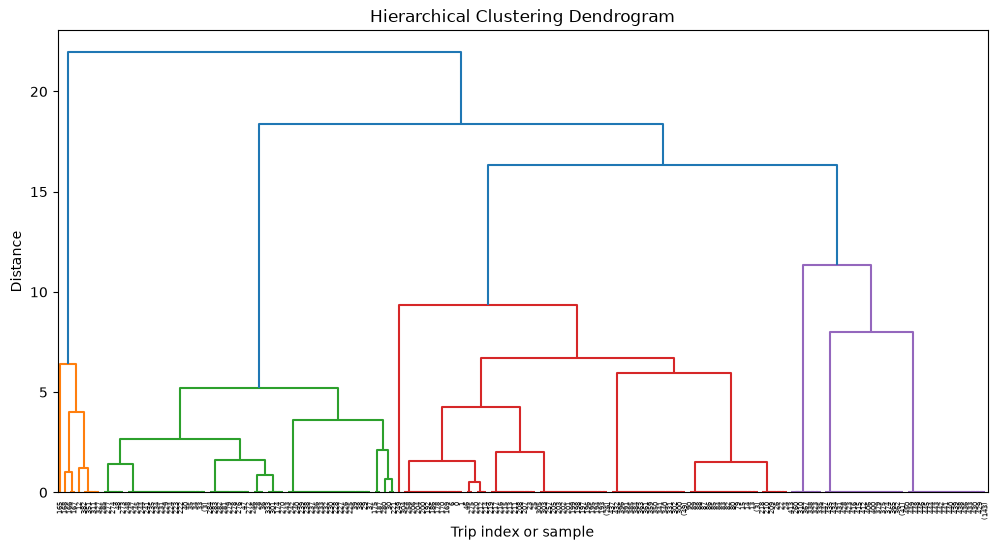

In [12]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Compute linkage matrix (Ward method matches your clustering)
Z = linkage(mca_coords_reduced, method='ward')

# Dendrogram plot
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='level', p=20, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Trip index or sample')
plt.ylabel('Distance')
plt.show()


In [13]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering

range_n_clusters = range(2, 10)
for n_clusters in range_n_clusters:
    clusterer = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
    cluster_labels = clusterer.fit_predict(mca_coords_reduced)
    silhouette_avg = silhouette_score(mca_coords_reduced, cluster_labels)
    print(f"n_clusters = {n_clusters}, silhouette_score = {silhouette_avg:.3f}")


n_clusters = 2, silhouette_score = 0.777
n_clusters = 3, silhouette_score = 0.501
n_clusters = 4, silhouette_score = 0.557
n_clusters = 5, silhouette_score = 0.588
n_clusters = 6, silhouette_score = 0.596
n_clusters = 7, silhouette_score = 0.683
n_clusters = 8, silhouette_score = 0.721
n_clusters = 9, silhouette_score = 0.722


## Apply hierarchical clustering

In [14]:
# Apply hierarchical clustering
from sklearn.cluster import AgglomerativeClustering

# Choose 5 clusters as initial guess
clusterer = AgglomerativeClustering(n_clusters=4, linkage='ward')
df_lvvi3['trip_type'] = clusterer.fit_predict(mca_coords_reduced)

/tmp/xuleyi11/ipykernel_2268102/565795430.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_lvvi3['trip_type'] = clusterer.fit_predict(mca_coords_reduced)


In [15]:
df_lvvi3['trip_type'].value_counts()

trip_type
0    223
1    156
2     63
3      9
Name: count, dtype: int64

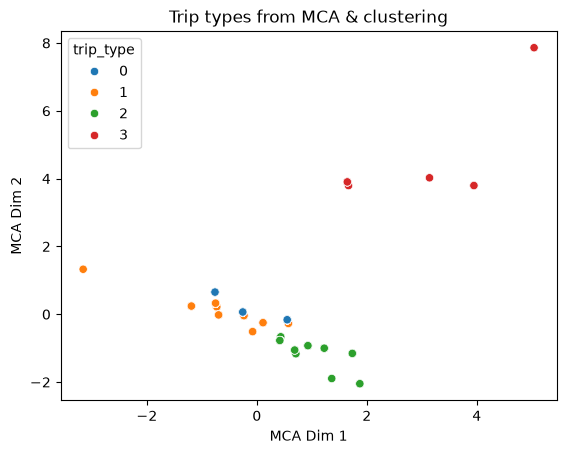

In [16]:
sns.scatterplot(x=mca_coords_reduced.iloc[:,0],
                y=mca_coords_reduced.iloc[:,1],
                hue=df_lvvi3['trip_type'],
                palette='tab10')
plt.xlabel('MCA Dim 1')
plt.ylabel('MCA Dim 2')
plt.title('Trip types from MCA & clustering')
plt.show()


## Profile trip type

### Activities

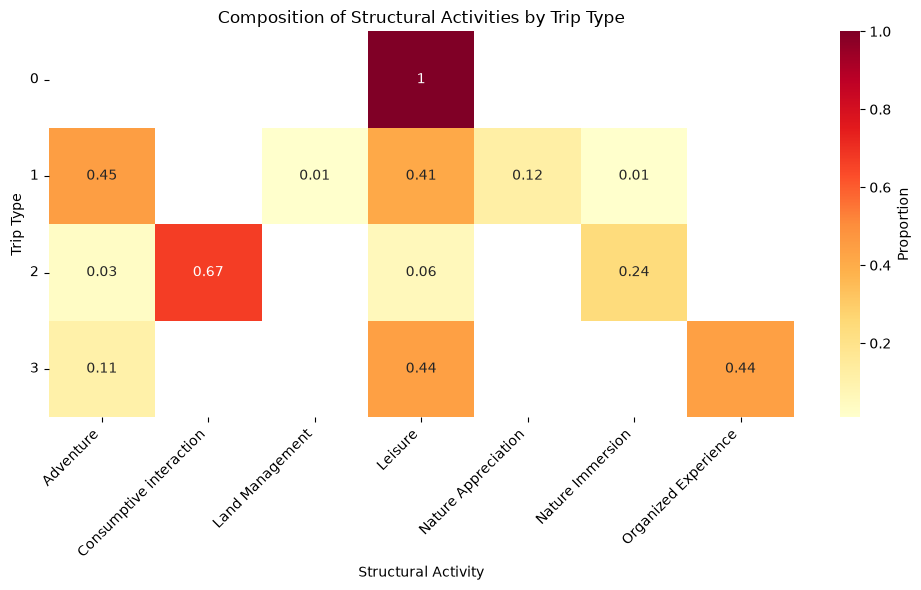

In [17]:
# Compute normalized composition of activities by trip type
activity_profile = df_lvvi3.groupby('trip_type')['structural_activity'].value_counts(normalize=True).unstack().round(2)

plt.figure(figsize=(10, 6))
sns.heatmap(activity_profile, annot=True, cmap='YlOrRd', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Structural Activities by Trip Type')
plt.ylabel('Trip Type')
plt.xlabel('Structural Activity')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

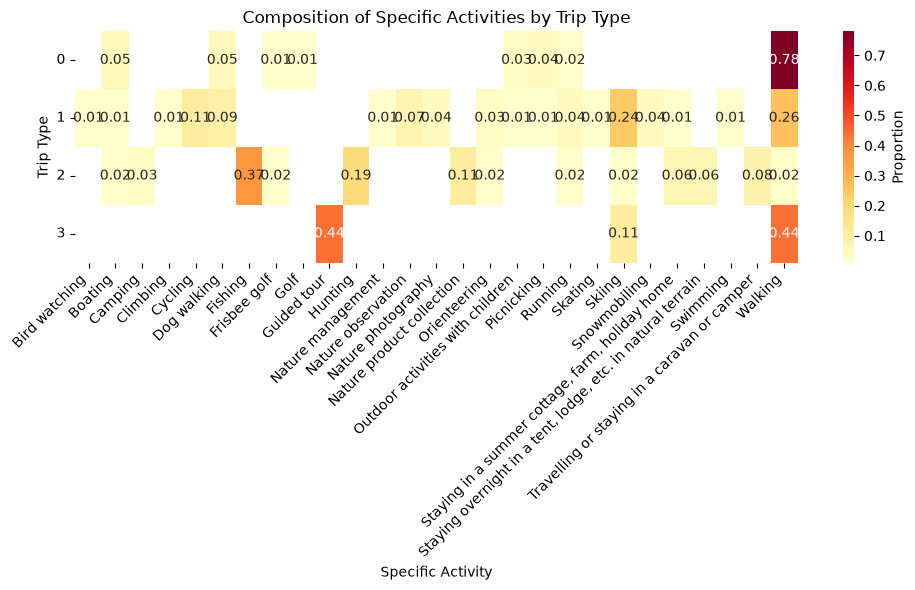

In [18]:
# Compute normalized composition of activities by trip type
activity_specific_profile = df_lvvi3.groupby('trip_type')['activity'].value_counts(normalize=True).unstack().round(2)

plt.figure(figsize=(10, 6))
sns.heatmap(activity_specific_profile, annot=True, cmap='YlOrRd', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Specific Activities by Trip Type')
plt.ylabel('Trip Type')
plt.xlabel('Specific Activity')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Accompany patterns

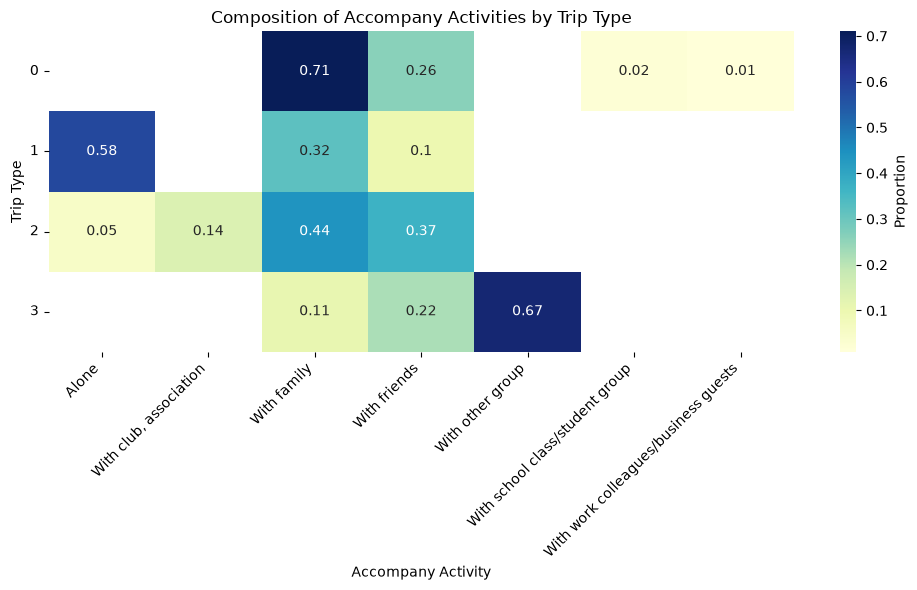

In [19]:
# Compute normalized composition of accompany patterns by trip type
accompany_profile = df_lvvi3.groupby('trip_type')['accompany'].value_counts(normalize=True).unstack().round(2)

plt.figure(figsize=(10, 6))
sns.heatmap(accompany_profile, annot=True, cmap='YlGnBu', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Accompany Activities by Trip Type')
plt.ylabel('Trip Type')
plt.xlabel('Accompany Activity')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# YouTube trip type identification

## Create video-level activity dataframe

In [20]:
# Group activities by video_id
df_youtube_agg = df_youtube.groupby("video_id")["structural_activity"].apply(lambda x: list(x.unique())).reset_index()
# Merge aggregated data with df_videos
df_youtube_videos = df_videos.merge(df_youtube_agg, on="video_id", how="left")
# Replace NaN with empty lists
df_youtube_videos['structural_activity'] = df_youtube_videos['structural_activity'].apply(lambda x: x if isinstance(x, list) else [])

# # Add accompany_type column
# df_youtube_videos = pd.merge(df_youtube_videos, df_youtube[['video_id', 'accompany_type']].drop_duplicates(), on='video_id', how='left')
df_youtube_videos = pd.merge(df_youtube_videos, df_youtube[['video_id', 'accompany_type']].drop_duplicates(), on='video_id', how='inner')

df_youtube_videos.shape

(3595, 13)

In [21]:
# df_youtube_videos['structural_activity'] = df_youtube_videos['structural_activity'].apply(
#     lambda x: x if isinstance(x, list) else []
# )
# df_youtube_videos = df_youtube_videos[
#     df_youtube_videos['structural_activity'].apply(len) > 0
# ]

# df_youtube_videos = df_youtube_videos.dropna()

import numpy as np

def clean_structural(x):
    # If not a list → return empty list
    if not isinstance(x, list):
        return []
    
    # Remove NaN / non-string elements inside list
    return [i for i in x if isinstance(i, str) and pd.notna(i)]

df_youtube_videos['structural_activity'] = df_youtube_videos['structural_activity'].apply(clean_structural)

df_youtube_videos[['video_id', 'structural_activity', 'accompany_type']]

,video_id,structural_activity,accompany_type
0,6kIs0Sl_9kM,"[Nature Immersion, Leisure]",With friends
1,b2oGnWClUSo,"[Land Management, Nature Appreciation, Adventu...",With work colleagues/business guests
2,ItzZmQFNTV0,[Leisure],With friends
3,zHCP9kU6G5M,"[Nature Immersion, Nature Appreciation, Leisure]",With friends
4,PncF467Lnlo,[Leisure],With friends
...,...,...,...
3590,8MMJyyUZj94,"[Leisure, Consumptive interaction, Nature Imme...",With family
3591,5YZXaGcAaZw,"[Leisure, Adventure]",With family
3592,qrNiOUMpkCo,"[Consumptive interaction, Leisure]",With friends
3593,9eSqbGJacfo,"[Nature Appreciation, Leisure]",With work colleagues/business guests


## Apply Multiple Correspondence Analysis (MCA) to transform categorical variables into numeri coordinates

In [22]:
# Convert list to multi-hot columns
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()

structural_dummies = pd.DataFrame(
    mlb.fit_transform(df_youtube_videos['structural_activity']),
    columns=mlb.classes_,
    index=df_youtube_videos.index
)

In [23]:
# One-hot encode accompany_type
accompany_dummies = pd.get_dummies(df_youtube_videos['accompany_type'], prefix='acc')

# Combine features
df_mca_yt = pd.concat([structural_dummies, accompany_dummies], axis=1)

# Treat binary as categorical
df_mca_yt = df_mca_yt.astype(str)

In [24]:
import prince

mca = prince.MCA(
    n_components=5,
    n_iter=10,
    random_state=42
)

mca = mca.fit(df_mca_yt)
mca_coords_yt = mca.transform(df_mca_yt)

In [25]:
# Decide the number of dimensions to retain
mca.percentage_of_variance_

array([12.66475667, 11.35903118,  9.59460055,  8.24471392,  7.55071162])

In [26]:
# Select MCA dimensions for clustering
mca_coords_reduced = mca_coords_yt.iloc[:, :3]

## Determine the number of clusters

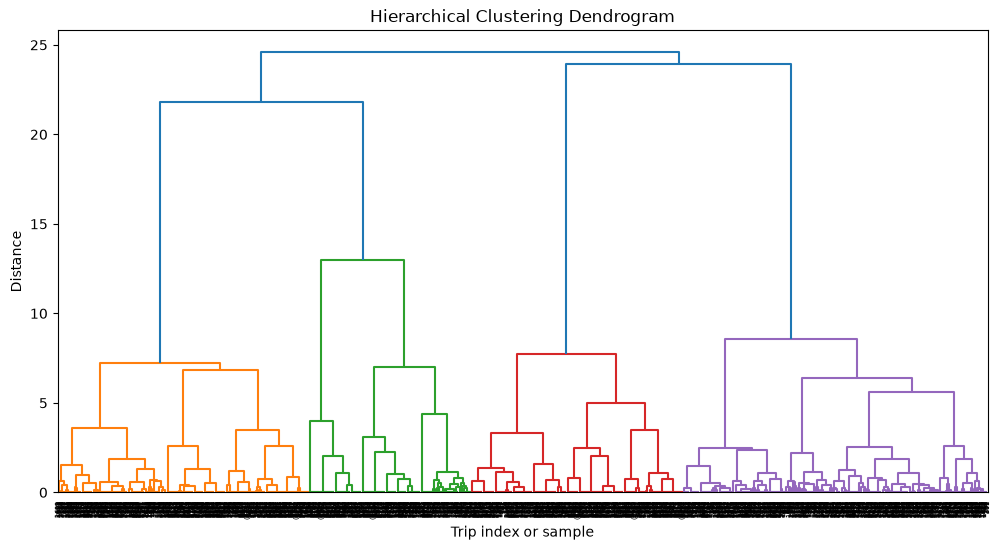

In [27]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Compute linkage matrix (Ward method matches your clustering)
Z = linkage(mca_coords_reduced, method='ward')

# Dendrogram plot
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='level', p=20, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Trip index or sample')
plt.ylabel('Distance')
plt.show()


In [28]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering

range_n_clusters = range(2, 10)
for n_clusters in range_n_clusters:
    clusterer = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
    cluster_labels = clusterer.fit_predict(mca_coords_reduced)
    silhouette_avg = silhouette_score(mca_coords_reduced, cluster_labels)
    print(f"n_clusters = {n_clusters}, silhouette_score = {silhouette_avg:.3f}")


n_clusters = 2, silhouette_score = 0.286


n_clusters = 3, silhouette_score = 0.383


n_clusters = 4, silhouette_score = 0.459


n_clusters = 5, silhouette_score = 0.477


n_clusters = 6, silhouette_score = 0.460


n_clusters = 7, silhouette_score = 0.418


n_clusters = 8, silhouette_score = 0.403


n_clusters = 9, silhouette_score = 0.419


## Apply hierarchical clustering

In [29]:
from sklearn.cluster import AgglomerativeClustering

clusterer = AgglomerativeClustering(n_clusters=4, linkage='ward')
df_youtube_videos['trip_type'] = clusterer.fit_predict(mca_coords_reduced)

In [30]:
df_youtube_videos['trip_type'].value_counts()

trip_type
2    1147
3     973
0     844
1     631
Name: count, dtype: int64

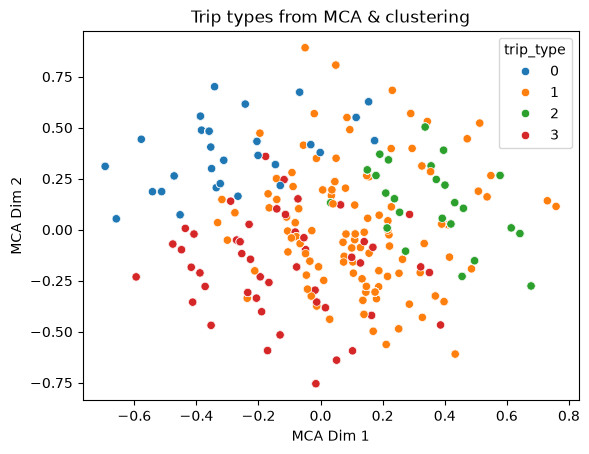

In [31]:
sns.scatterplot(x=mca_coords_reduced.iloc[:,0],
                y=mca_coords_reduced.iloc[:,1],
                hue=df_youtube_videos['trip_type'],
                palette='tab10')
plt.xlabel('MCA Dim 1')
plt.ylabel('MCA Dim 2')
plt.title('Trip types from MCA & clustering')
plt.show()

In [32]:
# Need to use original list column
df_exploded = df_youtube_videos.explode('structural_activity')

activity_profile = (
    df_exploded
    .groupby('trip_type')['structural_activity']
    .value_counts(normalize=True)
    .unstack()
    .round(2)
)

### Activities

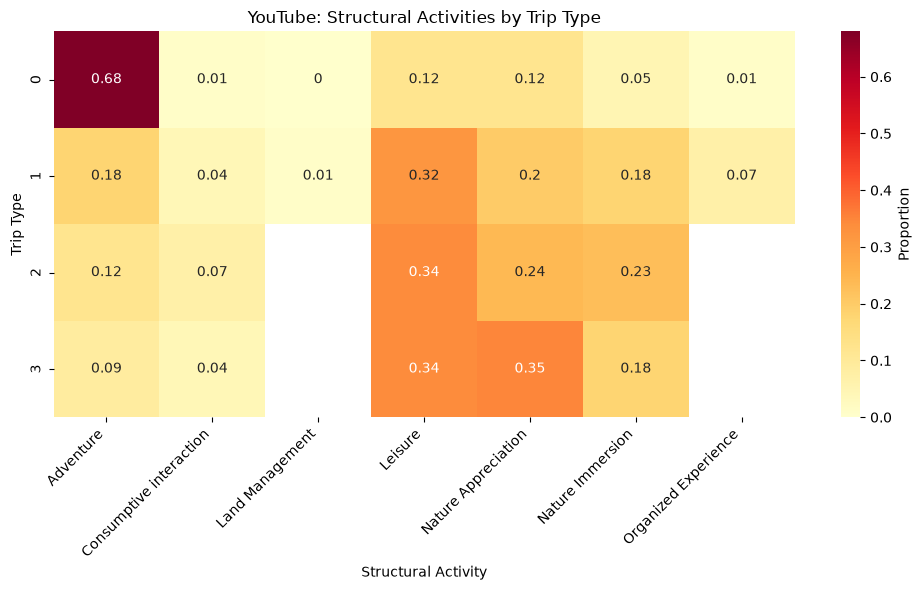

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(activity_profile, annot=True, cmap='YlOrRd',
            cbar_kws={'label': 'Proportion'})
plt.title('YouTube: Structural Activities by Trip Type')
plt.ylabel('Trip Type')
plt.xlabel('Structural Activity')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [34]:
acc_profile = (
    df_youtube_videos
    .groupby('trip_type')['accompany_type']
    .value_counts(normalize=True)
    .unstack()
    .round(2)
)

In [35]:
acc_profile

accompany_type,Alone,"With club, association",With family,With friends,With other group,With school class/student group,With work colleagues/business guests
trip_type,,,,,,,
0,0.38,0.01,0.03,0.56,NaN,0.00,0.02
1,0.01,0.06,0.72,0.11,NaN,0.03,0.07
2,NaN,NaN,NaN,1.00,NaN,NaN,NaN
3,0.99,NaN,NaN,NaN,0.01,NaN,NaN


### Accompany patterns

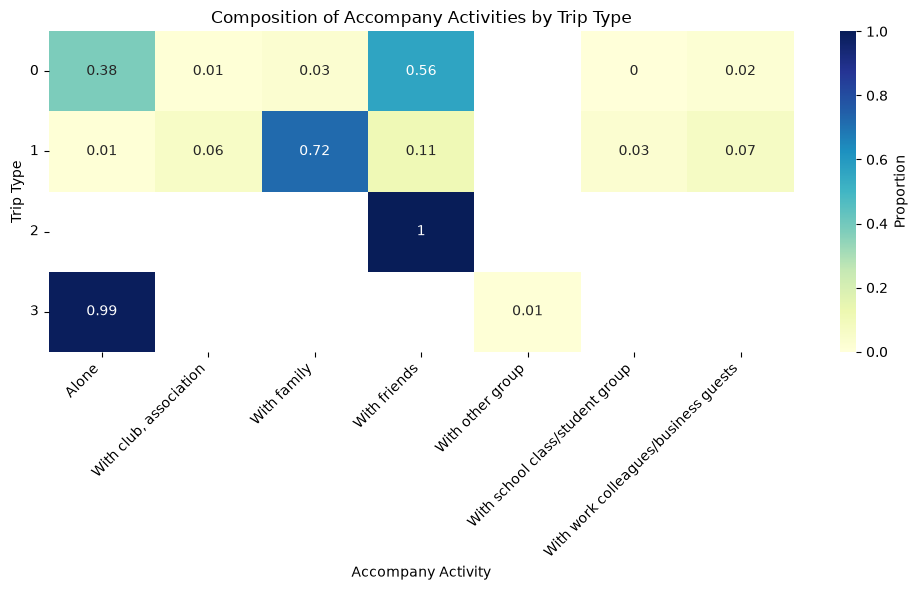

In [36]:
# Compute normalized composition of accompany patterns by trip type
accompany_profile = df_youtube_videos.groupby('trip_type')['accompany_type'].value_counts(normalize=True).unstack().round(2)

plt.figure(figsize=(10, 6))
sns.heatmap(accompany_profile, annot=True, cmap='YlGnBu', cbar_kws={'label': 'Proportion'})
plt.title('Composition of Accompany Activities by Trip Type')
plt.ylabel('Trip Type')
plt.xlabel('Accompany Activity')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Compare clusters across sources

## Joint clustering